# 03 — Linear baseline: OLS, Ridge and Elastic Net

**Goal:** the simplest regression model for RUL, so every later model (trees, LSTM, TCN) has a bar to beat.

Two feature sets, everything else identical:

| Version | Features | Source |
|---|---|---|
| **v1** | 3 operating settings + 21 raw sensors at the current cycle (24) | raw data |
| **v2** | `cycle` + 14 informative sensors + their trailing 10-cycle rolling mean, std and slope (57) | Aryan's `features.py` |

- **Protocol:** `docs/EVALUATION_PROTOCOL.md`: no RUL cap, 80/20 split by engine (seed 42), scored on the 100 validation cut-off rows.
- **Tuning rule:** hyperparameters are chosen by **validation RMSE** (big misses matter most for maintenance). The official test set is scored **once per feature set**, at the end, for the model chosen on validation.

Run this notebook from the `notebooks/` folder.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from scipy import stats
from sklearn.base import clone
from sklearn.linear_model import ElasticNet, LinearRegression, Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from rul_prediction.data import SENSOR_COLUMNS, SETTING_COLUMNS, load_cmapss_file, load_rul_file
from rul_prediction.features import (
    DEFAULT_WINDOW,
    add_rolling_features,
    model_feature_columns,
    select_informative_sensors,
)
from rul_prediction.metrics import score_predictions
from rul_prediction.splits import DEFAULT_SEED, sample_cutoff_rows, split_by_engine, split_engine_ids
from rul_prediction.targets import add_train_rul, attach_test_rul, last_observed_rows

RAW_DIR = PROJECT_ROOT / "data" / "raw"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
RESULTS_DIR = PROJECT_ROOT / "reports" / "results"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

## 1. Target, split, features and validation points

Target and split come from the shared modules. Sensor selection is fitted on the 80 training engines only. Rolling features are trailing windows inside each engine, so they are built on each split separately and only **then** are the validation cut-off rows sampled (protocol §3). The assert checks the 100 points against the committed `docs/fd001_validation_cutoffs.csv`.

In [2]:
train = add_train_rul(load_cmapss_file(RAW_DIR / "train_FD001.txt"))
train_ids, val_ids = split_engine_ids(train["engine_id"])
train_raw, val_raw = split_by_engine(train, val_ids)

sensors = select_informative_sensors(train_raw)
train_df = add_rolling_features(train_raw, sensors)
val_df = add_rolling_features(val_raw, sensors)
val_points = sample_cutoff_rows(val_df)

expected_points = pd.read_csv(PROJECT_ROOT / "docs" / "fd001_validation_cutoffs.csv")
pd.testing.assert_frame_equal(val_points[["engine_id", "cycle", "rul"]], expected_points)

FEATURE_SETS = {
    "v1": SETTING_COLUMNS + SENSOR_COLUMNS,
    "v2": model_feature_columns(sensors, DEFAULT_WINDOW),
}
FEATURE_SET_DESCRIPTIONS = {
    "v1": "raw settings + sensors (24)",
    "v2": f"cycle + {len(sensors)} sensors + rolling mean/std/slope w{DEFAULT_WINDOW} ({len(FEATURE_SETS['v2'])})",
}

print(f"train engines: {len(train_ids)}, rows: {len(train_df)}")
print(f"validation engines: {len(val_ids)}, rows: {len(val_df)}, cut-off points: {len(val_points)}")
for feature_set, description in FEATURE_SET_DESCRIPTIONS.items():
    print(f"{feature_set}: {description}")

train engines: 80, rows: 16390
validation engines: 20, rows: 4241, cut-off points: 100
v1: raw settings + sensors (24)
v2: cycle + 14 sensors + rolling mean/std/slope w10 (57)


## 2. Models

| Model | Fits | Hyperparameter |
|---|---|---|
| **OLS** (`LinearRegression`) | Minimises squared error only | none |
| **Ridge** | Squared error + alpha × sum of squared coefficients (L2) | `alpha`: bigger = coefficients shrunk harder towards 0 |
| **Elastic Net** | Squared error + mix of L1 (sum of absolute coefficients) and L2 | `alpha` (strength), `l1_ratio` (share of L1; L1 can set coefficients exactly to 0) |

**Why scale first:** the penalty compares coefficient sizes, so features must be on the same scale or the penalty would unfairly hit features measured in small units. The scaler sits inside the pipeline, so `fit` learns the mean/std from the 80 training engines only.

Grids are kept small on purpose: we tune on one fixed validation split, and a big grid would overfit it. The same grid is used for both feature sets.

In [3]:
RIDGE_ALPHAS = [0.01, 0.1, 1, 10, 100, 1000]
ELASTIC_NET_ALPHAS = [0.001, 0.01, 0.1, 1]
ELASTIC_NET_L1_RATIOS = [0.2, 0.5, 0.8]

candidates = [("OLS", {}, LinearRegression())]
candidates += [("Ridge", {"alpha": a}, Ridge(alpha=a)) for a in RIDGE_ALPHAS]
candidates += [
    ("ElasticNet", {"alpha": a, "l1_ratio": r}, ElasticNet(alpha=a, l1_ratio=r, max_iter=50_000))
    for a in ELASTIC_NET_ALPHAS
    for r in ELASTIC_NET_L1_RATIOS
]


def fit_on_train_engines(model, features):
    """Scaler + a fresh copy of the model, fitted on the 80 training engines only."""
    return make_pipeline(StandardScaler(), clone(model)).fit(train_df[features], train_df["rul"])


def params_key(params):
    return tuple(sorted(params.items()))


rows, fitted = [], {}
for feature_set, features in FEATURE_SETS.items():
    for name, params, model in candidates:
        pipeline = fit_on_train_engines(model, features)
        cutoff = score_predictions(val_points["rul"], pipeline.predict(val_points[features]))
        all_rows = score_predictions(val_df["rul"], pipeline.predict(val_df[features]))
        fitted[(feature_set, name, params_key(params))] = pipeline
        rows.append({
            "feature_set": feature_set,
            "model": name,
            "params": params,
            "val_mae": cutoff["mae"],
            "val_rmse": cutoff["rmse"],
            "val_n": cutoff["n"],
            "val_all_rows_mae": all_rows["mae"],
            "val_all_rows_rmse": all_rows["rmse"],
        })

grid = pd.DataFrame(rows)
grid.round(2).sort_values(["feature_set", "val_rmse"])

,feature_set,model,params,val_mae,val_rmse,val_n,val_all_rows_mae,val_all_rows_rmse
0,v1,OLS,{},32.86,42.92,100,36.36,49.72
1,v1,Ridge,{'alpha': 0.01},32.86,42.92,100,36.36,49.72
2,v1,Ridge,{'alpha': 0.1},32.86,42.92,100,36.36,49.72
3,v1,Ridge,{'alpha': 1},32.87,42.92,100,36.36,49.72
4,v1,Ridge,{'alpha': 10},32.87,42.92,100,36.36,49.72
7,v1,ElasticNet,"{'alpha': 0.001, 'l1_ratio': 0.2}",32.87,42.92,100,36.36,49.72
8,v1,ElasticNet,"{'alpha': 0.001, 'l1_ratio': 0.5}",32.87,42.92,100,36.36,49.72
9,v1,ElasticNet,"{'alpha': 0.001, 'l1_ratio': 0.8}",32.87,42.92,100,36.36,49.72
12,v1,ElasticNet,"{'alpha': 0.01, 'l1_ratio': 0.8}",32.87,42.92,100,36.36,49.72
5,v1,Ridge,{'alpha': 100},32.88,42.93,100,36.36,49.72


## 3. Choose the model on validation only

Best setting per model family by validation RMSE, then the winner within each feature set. These choices are final before the test set is touched.

In [4]:
best_per_family = (
    grid.loc[grid.groupby(["feature_set", "model"])["val_rmse"].idxmin()]
    .sort_values(["feature_set", "val_rmse"])
    .reset_index(drop=True)
)
chosen = best_per_family.loc[best_per_family.groupby("feature_set")["val_rmse"].idxmin()].set_index("feature_set")
chosen_pipelines = {
    feature_set: fitted[(feature_set, row["model"], params_key(row["params"]))]
    for feature_set, row in chosen.iterrows()
}


def model_label(feature_set):
    row = chosen.loc[feature_set]
    return f"{feature_set} {row['model']}" + (f" {row['params']}" if row["params"] else "")


for feature_set in FEATURE_SETS:
    print("chosen:", model_label(feature_set))
best_per_family.round(2)

chosen: v1 OLS
chosen: v2 ElasticNet {'alpha': 1, 'l1_ratio': 0.5}


,feature_set,model,params,val_mae,val_rmse,val_n,val_all_rows_mae,val_all_rows_rmse
0,v1,OLS,{},32.86,42.92,100,36.36,49.72
1,v1,Ridge,{'alpha': 0.01},32.86,42.92,100,36.36,49.72
2,v1,ElasticNet,"{'alpha': 0.001, 'l1_ratio': 0.8}",32.87,42.92,100,36.36,49.72
3,v2,ElasticNet,"{'alpha': 1, 'l1_ratio': 0.5}",31.66,41.77,100,34.60,47.25
4,v2,Ridge,{'alpha': 1000},31.93,41.89,100,34.98,47.23
5,v2,OLS,{},32.66,42.54,100,35.48,47.65


## 3b. What drives the v2 gain? (validation-only ablation)

v2 differs from v1 in three ways at once: it adds `cycle`, adds rolling features, and drops the operating settings and flat sensors. To see which part matters, the chosen v2 model specification is refit on subsets of the v2 inputs. **Analysis only:** these rows are not candidates, do not change the chosen model, and are never scored on the test set.

In [5]:
v2_model = chosen_pipelines["v2"][-1]
v2_without_cycle = [f for f in FEATURE_SETS["v2"] if f != "cycle"]
ablation_inputs = {
    "v2 full (cycle + sensors + rolling)": FEATURE_SETS["v2"],
    "v2 without cycle (sensors + rolling)": v2_without_cycle,
    "cycle + 14 raw sensors (no rolling)": ["cycle"] + sensors,
    "14 raw sensors only": list(sensors),
}
ablation = pd.DataFrame([
    {
        "inputs": name,
        "n_features": len(columns),
        **score_predictions(
            val_points["rul"],
            fit_on_train_engines(v2_model, columns).predict(val_points[columns]),
        ),
    }
    for name, columns in ablation_inputs.items()
]).set_index("inputs")
print("model spec:", model_label("v2"))
ablation.round(2)

model spec: v2 ElasticNet {'alpha': 1, 'l1_ratio': 0.5}


,n_features,mae,rmse,n
inputs,,,,
v2 full (cycle + sensors + rolling),57,31.66,41.77,100
v2 without cycle (sensors + rolling),56,33.06,43.33,100
cycle + 14 raw sensors (no rolling),15,31.42,41.74,100
14 raw sensors only,14,33.33,43.46,100


## 4. Regularization (v1 analysis)

Ridge coefficient path on the v1 features: each line is one feature's coefficient (on scaled features) as `alpha` grows. At small `alpha` Ridge equals OLS; as `alpha` grows, coefficients shrink overall. With correlated sensors the paths are not monotonic: some coefficients first grow while their correlated partners shrink. The grey band is the alpha range tried in the tuning grid.

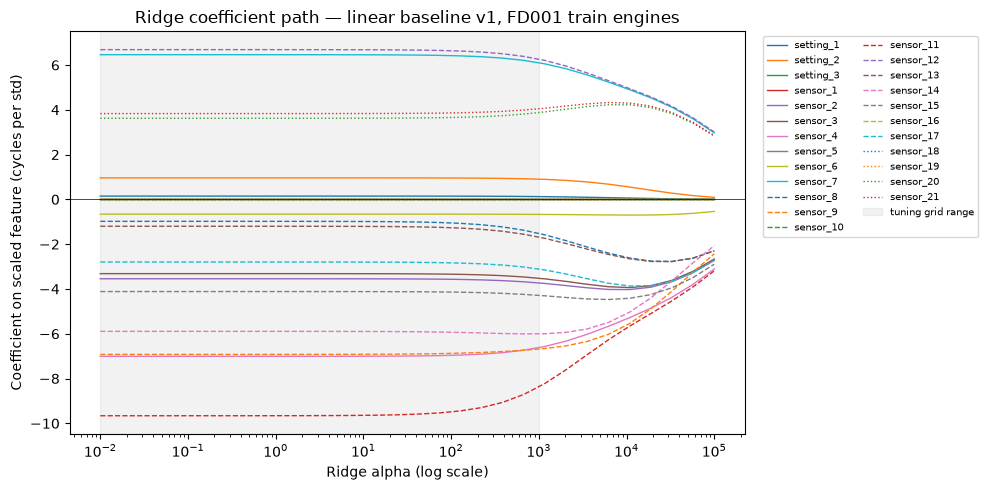

In [6]:
V1 = FEATURE_SETS["v1"]
path_alphas = np.logspace(-2, 5, 30)
path = pd.DataFrame(
    [fit_on_train_engines(Ridge(alpha=a), V1)[-1].coef_ for a in path_alphas],
    index=path_alphas,
    columns=V1,
)

fig, ax = plt.subplots(figsize=(10, 5))
line_styles = ["-", "--", ":"]
for i, feature in enumerate(path.columns):
    ax.plot(path.index, path[feature], linewidth=1, linestyle=line_styles[i // 10], label=feature)
ax.axvspan(min(RIDGE_ALPHAS), max(RIDGE_ALPHAS), color="grey", alpha=0.1, label="tuning grid range")
ax.set_xscale("log")
ax.set_xlabel("Ridge alpha (log scale)")
ax.set_ylabel("Coefficient on scaled feature (cycles per std)")
ax.set_title("Ridge coefficient path — linear baseline v1, FD001 train engines")
ax.axhline(0, color="black", linewidth=0.5)
ax.legend(fontsize=7, ncol=2, bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "linear_ridge_coefficient_path.png", dpi=150)
plt.show()

In [7]:
v1_best = best_per_family[best_per_family["feature_set"] == "v1"]
coefficients = pd.DataFrame({
    row["model"]: fitted[("v1", row["model"], params_key(row["params"]))][-1].coef_
    for _, row in v1_best.iterrows()
}, index=V1)

# A sensor that never changes carries no information: after scaling it is all
# zeros, so every model gives it a ~0 coefficient. That is not regularization.
constant_in_train = [f for f in V1 if train_df[f].nunique() == 1]
print("constant in training engines:", constant_in_train)

# Demo only (not a tuning candidate): a strong L1 penalty sets extra
# coefficients exactly to 0, which is how Elastic Net / Lasso select features.
coefficients["ElasticNet a=1, l1=0.8 (demo)"] = fit_on_train_engines(
    ElasticNet(alpha=1, l1_ratio=0.8, max_iter=50_000), V1
)[-1].coef_

near_zero = (coefficients.abs() < 1e-6).sum()
print("coefficients ~0 (|coef| < 1e-6):", near_zero.to_dict())
coefficients.round(2)

constant in training engines: ['setting_3', 'sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']
coefficients ~0 (|coef| < 1e-6): {'OLS': 7, 'Ridge': 7, 'ElasticNet': 7, 'ElasticNet a=1, l1=0.8 (demo)': 8}


,OLS,Ridge,ElasticNet,"ElasticNet a=1, l1=0.8 (demo)"
setting_1,0.15,0.15,0.15,0.00
setting_2,0.96,0.96,0.96,0.11
setting_3,0.00,0.00,0.00,0.00
sensor_1,0.00,0.00,0.00,0.00
sensor_2,-3.54,-3.54,-3.55,-3.86
sensor_3,-3.32,-3.32,-3.32,-3.68
sensor_4,-7.01,-7.01,-7.01,-6.16
sensor_5,-0.00,0.00,0.00,0.00
sensor_6,-0.66,-0.66,-0.66,-0.12
sensor_7,6.46,6.46,6.46,5.60


## 4b. Underfitting or overfitting? Train vs validation error

If a model **overfits** (high variance), training error is much lower than validation error, and regularization should help. If it **underfits** (high bias), both errors are high and close. Compared on all rows, because the cut-off points exist only for validation engines.

In [8]:
fit_check = pd.DataFrame([
    {
        "feature_set": feature_set,
        "rows": label,
        **score_predictions(table["rul"], chosen_pipelines[feature_set].predict(table[FEATURE_SETS[feature_set]])),
    }
    for feature_set in FEATURE_SETS
    for label, table in [("train (80 engines, all rows)", train_df), ("validation (20 engines, all rows)", val_df)]
]).set_index(["feature_set", "rows"])
fit_check.round(2)

mae   rmse      n
feature_set rows                                                  
v1          train (80 engines, all rows)       33.33  43.31  16390
            validation (20 engines, all rows)  36.36  49.72   4241
v2          train (80 engines, all rows)       30.11  39.30  16390
            validation (20 engines, all rows)  34.60  47.25   4241

## 4c. Multicollinearity between raw sensors (v1)

Correlated inputs make individual linear coefficients unstable and hard to interpret (an assumption check from the concept map). Pearson correlation on the training engines, constant features excluded. v2 adds a rolling mean of every sensor, which is by construction highly correlated with the raw reading, so the same caution applies even more to v2 coefficients.

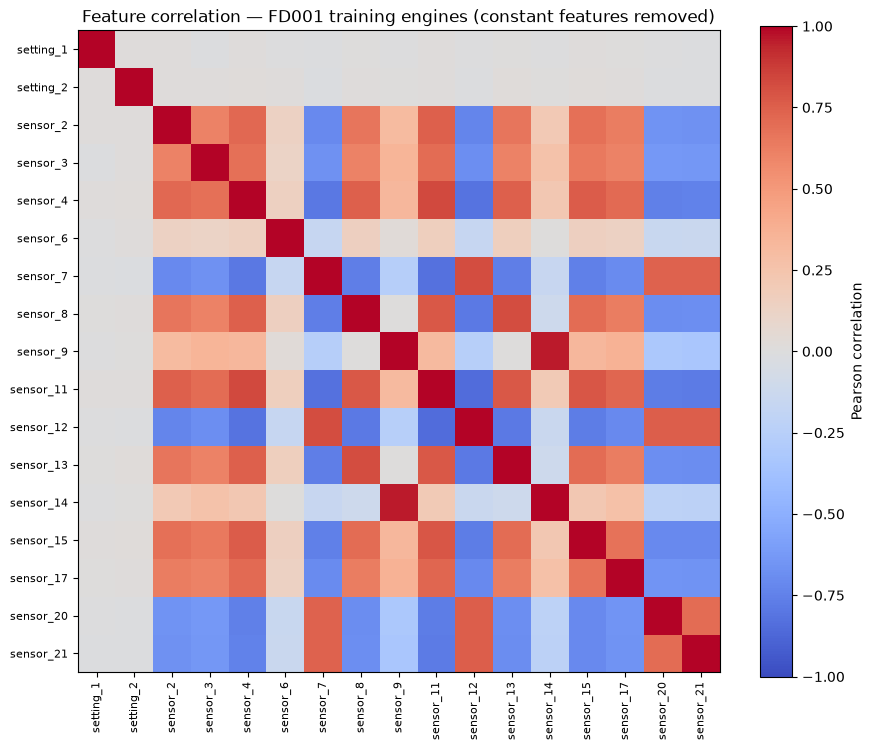

feature pairs with |correlation| >= 0.8: 7


,,correlation
sensor_9,sensor_14,0.96
sensor_11,sensor_12,-0.85
sensor_4,sensor_11,0.83
sensor_7,sensor_11,-0.82
sensor_8,sensor_13,0.82
sensor_4,sensor_12,-0.82
sensor_7,sensor_12,0.82


In [9]:
informative = [f for f in V1 if f not in constant_in_train]
correlation = train_df[informative].corr()

fig, ax = plt.subplots(figsize=(9, 7.5))
image = ax.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(informative)), informative, rotation=90, fontsize=8)
ax.set_yticks(range(len(informative)), informative, fontsize=8)
fig.colorbar(image, ax=ax, label="Pearson correlation")
ax.set_title("Feature correlation — FD001 training engines (constant features removed)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "linear_feature_correlation.png", dpi=150)
plt.show()

pairs = correlation.where(np.triu(np.ones(correlation.shape, dtype=bool), k=1)).stack()
strong_pairs = pairs[pairs.abs() >= 0.8].sort_values(key=abs, ascending=False)
print(f"feature pairs with |correlation| >= 0.8: {len(strong_pairs)}")
strong_pairs.round(2).to_frame("correlation")

## 4d. Does a single sensor reading tell early life apart? (v1)

The sensor with the largest v1 OLS coefficient, plotted against true RUL for all training rows. If its values are flat for large RUL, a model using only the current reading cannot separate RUL 200 from RUL 300.

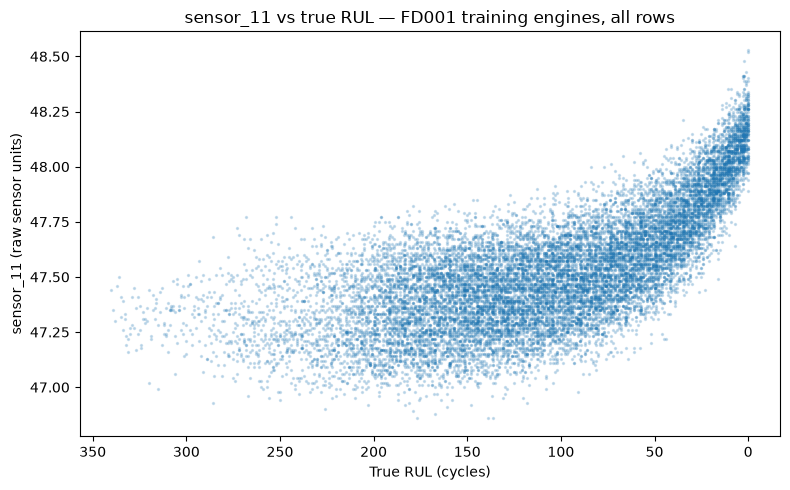

largest |OLS coefficient| (v1): sensor_11


In [10]:
top_sensor = coefficients["OLS"].abs().idxmax()

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(train_df["rul"], train_df[top_sensor], s=2, alpha=0.2)
ax.set_xlabel("True RUL (cycles)")
ax.set_ylabel(f"{top_sensor} (raw sensor units)")
ax.set_title(f"{top_sensor} vs true RUL — FD001 training engines, all rows")
ax.invert_xaxis()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "linear_top_sensor_vs_rul.png", dpi=150)
plt.show()

print("largest |OLS coefficient| (v1):", top_sensor)

## 5. Diagnostics on validation (chosen model of each feature set)

Checks from the concept map's *assumptions of linear regression*:

- **Predicted vs actual:** points on the diagonal = perfect.
- **Residuals vs predicted:** a curve means the relationship is not linear; a funnel means non-constant variance.
- **Residual histogram and Q-Q plot:** how far residuals are from normal.

Residual = actual RUL − predicted RUL (positive = model said the engine fails sooner than it does).

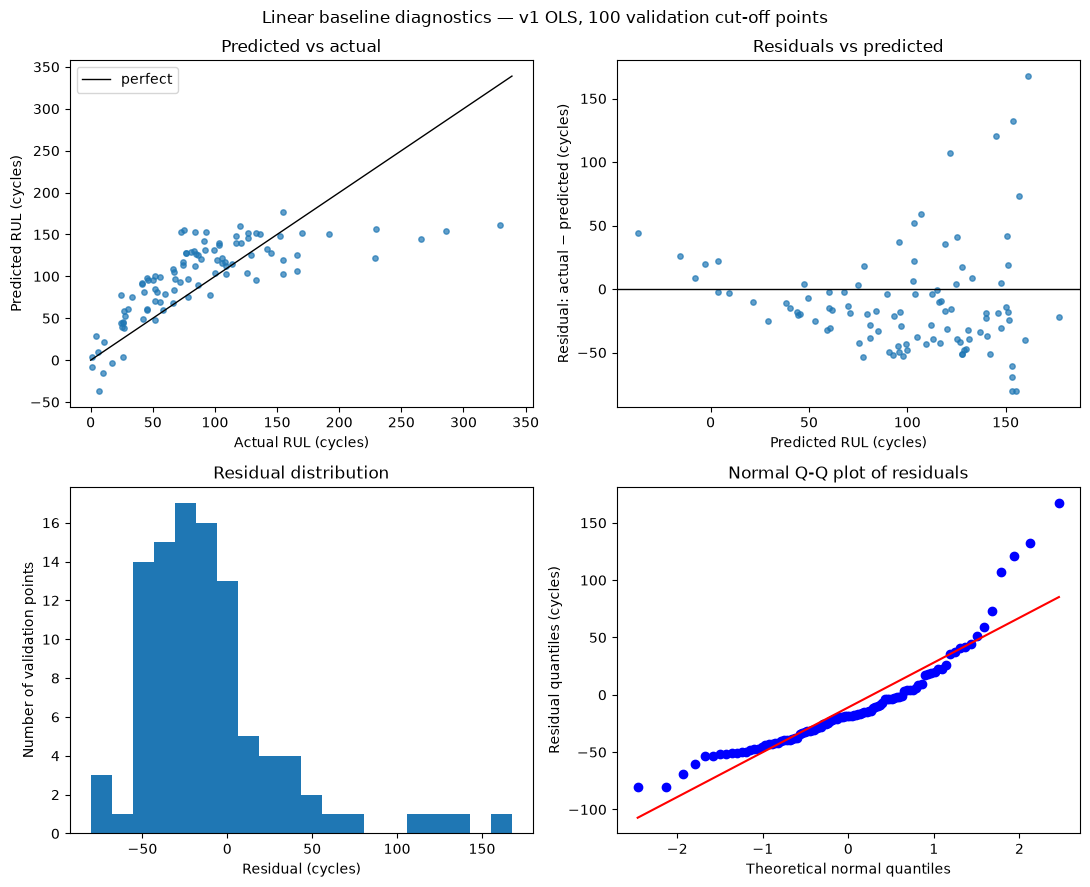

v1: negative RUL predictions: 4 of 100


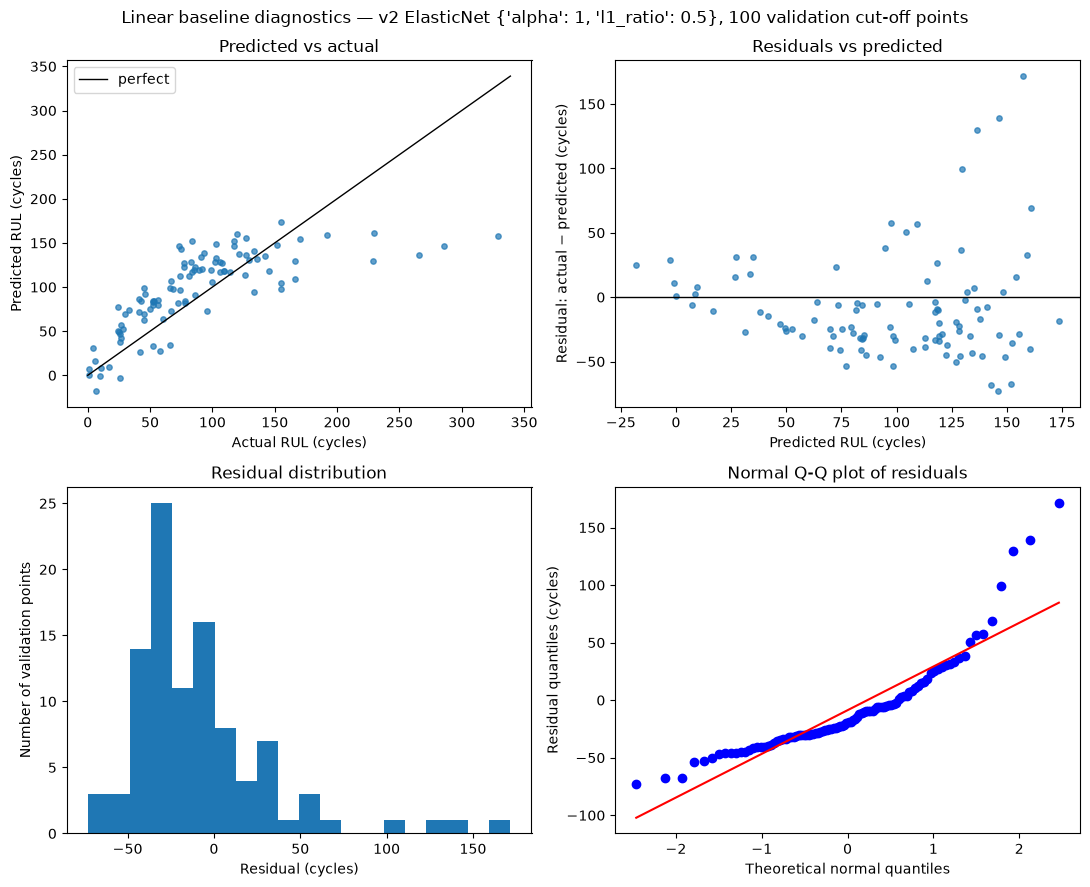

v2: negative RUL predictions: 3 of 100


In [11]:
DIAGNOSTIC_FIGURES = {
    "v1": "linear_baseline_validation_diagnostics.png",
    "v2": "linear_baseline_v2_validation_diagnostics.png",
}


def plot_validation_diagnostics(feature_set):
    """Four diagnostic panels for the chosen model of one feature set; returns predictions."""
    val_pred = chosen_pipelines[feature_set].predict(val_points[FEATURE_SETS[feature_set]])
    residuals = val_points["rul"] - val_pred

    fig, axes = plt.subplots(2, 2, figsize=(11, 9))

    limit = max(val_points["rul"].max(), val_pred.max()) + 10
    axes[0, 0].scatter(val_points["rul"], val_pred, s=15, alpha=0.7)
    axes[0, 0].plot([0, limit], [0, limit], color="black", linewidth=1, label="perfect")
    axes[0, 0].set_xlabel("Actual RUL (cycles)")
    axes[0, 0].set_ylabel("Predicted RUL (cycles)")
    axes[0, 0].set_title("Predicted vs actual")
    axes[0, 0].legend()

    axes[0, 1].scatter(val_pred, residuals, s=15, alpha=0.7)
    axes[0, 1].axhline(0, color="black", linewidth=1)
    axes[0, 1].set_xlabel("Predicted RUL (cycles)")
    axes[0, 1].set_ylabel("Residual: actual − predicted (cycles)")
    axes[0, 1].set_title("Residuals vs predicted")

    axes[1, 0].hist(residuals, bins=20)
    axes[1, 0].set_xlabel("Residual (cycles)")
    axes[1, 0].set_ylabel("Number of validation points")
    axes[1, 0].set_title("Residual distribution")

    stats.probplot(residuals, dist="norm", plot=axes[1, 1])
    axes[1, 1].set_title("Normal Q-Q plot of residuals")
    axes[1, 1].set_xlabel("Theoretical normal quantiles")
    axes[1, 1].set_ylabel("Residual quantiles (cycles)")

    fig.suptitle(f"Linear baseline diagnostics — {model_label(feature_set)}, 100 validation cut-off points")
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / DIAGNOSTIC_FIGURES[feature_set], dpi=150)
    plt.show()
    return val_pred


for feature_set in FEATURE_SETS:
    val_pred = plot_validation_diagnostics(feature_set)
    print(f"{feature_set}: negative RUL predictions: {(val_pred < 0).sum()} of {len(val_pred)}")

## 6. Final test evaluation (run once per feature set)

The chosen models above are fixed. Test features are built from `test_FD001.txt` alone with the sensor list chosen on the training engines. Each test engine is predicted at its last observed cycle and joined to `RUL_FD001.txt` by `engine_id`. Do not change a model after reading its number.

In [12]:
test_features = add_rolling_features(load_cmapss_file(RAW_DIR / "test_FD001.txt"), sensors)
test_points = attach_test_rul(last_observed_rows(test_features), load_rul_file(RAW_DIR / "RUL_FD001.txt"))

test_scores = {
    feature_set: score_predictions(
        test_points["rul"], chosen_pipelines[feature_set].predict(test_points[FEATURE_SETS[feature_set]])
    )
    for feature_set in FEATURE_SETS
}
pd.DataFrame(test_scores).T

,mae,rmse,n
v1,24.908041,31.173574,100.0
v2,23.613119,29.037771,100.0


## 7. Save results

Everything below is written from the variables above, so no number is typed by hand.

In [13]:
split_description = f"engine ID 80/20, seed {DEFAULT_SEED}, 100 val cut-offs (docs/fd001_validation_cutoffs.csv)"

summary = best_per_family.assign(
    features=best_per_family["feature_set"].map(FEATURE_SET_DESCRIPTIONS),
    target="RUL = last cycle - cycle, no cap",
    split=split_description,
    test_mae=np.nan,
    test_rmse=np.nan,
    test_n=np.nan,
)
for feature_set, row in chosen.iterrows():
    is_chosen = (summary["feature_set"] == feature_set) & (summary["model"] == row["model"])
    scores = test_scores[feature_set]
    summary.loc[is_chosen, ["test_mae", "test_rmse", "test_n"]] = [scores["mae"], scores["rmse"], scores["n"]]

grid.to_csv(RESULTS_DIR / "linear_baseline_grid.csv", index=False)
summary.to_csv(RESULTS_DIR / "linear_baseline_results.csv", index=False)

EXPERIMENTS = {
    "v1": {
        "log_file": "linear_baseline_experiment_log.md",
        "question": "How well does a linear model on raw settings + sensors predict RUL, and does regularization help?",
        "changed": "first model",
    },
    "v2": {
        "log_file": "linear_baseline_v2_experiment_log.md",
        "question": "Do Aryan's engineered features (cycle + rolling mean/std/slope) improve the linear baseline?",
        "changed": "features only: v1 raw settings + sensors -> v2 engineered features; same split, grids and seed",
    },
}


def write_experiment_log(feature_set):
    row, scores, info = chosen.loc[feature_set], test_scores[feature_set], EXPERIMENTS[feature_set]
    log = f"""# Experiment log — linear baseline {feature_set}

- **Owner:** Abhayanth
- **Notebook:** notebooks/03_linear_baseline.ipynb
- **Question:** {info["question"]}
- **Dataset/subset:** FD001
- **Split protocol / engine IDs:** {split_description}; validation engines {val_ids}
- **Target settings (including any RUL cap):** RUL = last cycle - cycle, no cap
- **Features or window length:** {FEATURE_SET_DESCRIPTIONS[feature_set]}: {", ".join(FEATURE_SETS[feature_set])}
- **Model:** StandardScaler + {row["model"]} (chosen by validation RMSE among OLS, Ridge, ElasticNet)
- **Hyperparameters:** {row["params"]}; grids: Ridge alpha {RIDGE_ALPHAS}, ElasticNet alpha {ELASTIC_NET_ALPHAS} x l1_ratio {ELASTIC_NET_L1_RATIOS}
- **Random seed:** {DEFAULT_SEED} (split and cut-offs; models are deterministic)
- **Other settings:** StandardScaler defaults (mean/std from training engines); ElasticNet max_iter=50000; scikit-learn {sklearn.__version__}, scipy {scipy.__version__}, pandas {pd.__version__}, numpy {np.__version__}
- **Validation MAE / RMSE (cycles, 100 cut-offs):** {row["val_mae"]:.2f} / {row["val_rmse"]:.2f}
- **Test MAE / RMSE (cycles, 100 engines, run once):** {scores["mae"]:.2f} / {scores["rmse"]:.2f}
- **Plots/results file:** reports/figures/{DIAGNOSTIC_FIGURES[feature_set]}, reports/results/linear_baseline_results.csv, reports/results/linear_baseline_grid.csv
- **What changed from previous experiment:** {info["changed"]}
- **Interpretation:** see the Findings section of the notebook
- **Limitations / next experiment:** RUL cap or refitting on all 100 training engines only as separate logged team decisions
"""
    (RESULTS_DIR / info["log_file"]).write_text(log)


for feature_set in FEATURE_SETS:
    write_experiment_log(feature_set)
summary.round(2)

,feature_set,model,params,val_mae,val_rmse,val_n,val_all_rows_mae,val_all_rows_rmse,features,target,split,test_mae,test_rmse,test_n
0,v1,OLS,{},32.86,42.92,100,36.36,49.72,raw settings + sensors (24),"RUL = last cycle - cycle, no cap","engine ID 80/20, seed 42, 100 val cut-offs (do...",24.91,31.17,100.0
1,v1,Ridge,{'alpha': 0.01},32.86,42.92,100,36.36,49.72,raw settings + sensors (24),"RUL = last cycle - cycle, no cap","engine ID 80/20, seed 42, 100 val cut-offs (do...",NaN,NaN,NaN
2,v1,ElasticNet,"{'alpha': 0.001, 'l1_ratio': 0.8}",32.87,42.92,100,36.36,49.72,raw settings + sensors (24),"RUL = last cycle - cycle, no cap","engine ID 80/20, seed 42, 100 val cut-offs (do...",NaN,NaN,NaN
3,v2,ElasticNet,"{'alpha': 1, 'l1_ratio': 0.5}",31.66,41.77,100,34.60,47.25,cycle + 14 sensors + rolling mean/std/slope w1...,"RUL = last cycle - cycle, no cap","engine ID 80/20, seed 42, 100 val cut-offs (do...",23.61,29.04,100.0
4,v2,Ridge,{'alpha': 1000},31.93,41.89,100,34.98,47.23,cycle + 14 sensors + rolling mean/std/slope w1...,"RUL = last cycle - cycle, no cap","engine ID 80/20, seed 42, 100 val cut-offs (do...",NaN,NaN,NaN
5,v2,OLS,{},32.66,42.54,100,35.48,47.65,cycle + 14 sensors + rolling mean/std/slope w1...,"RUL = last cycle - cycle, no cap","engine ID 80/20, seed 42, 100 val cut-offs (do...",NaN,NaN,NaN


## Findings

_All numbers come from the cell outputs above. Validation = the 100 shared cut-off points unless stated otherwise. Units: cycles._

| | v1 (raw, 24) | v2 (engineered, 57) |
|---|---|---|
| Chosen model | OLS | Elastic Net (alpha 1, l1_ratio 0.5) |
| Validation MAE / RMSE | 32.86 / 42.92 | 31.66 / 41.77 |
| Validation, all rows RMSE | 49.72 | 47.25 |
| Train, all rows RMSE | 43.31 | 39.30 |
| Test MAE / RMSE (scored once) | 24.91 / 31.17 | 23.61 / 29.04 |

**1. v2 is slightly better, and the gain comes from `cycle`, not the rolling features.**
- v2 lowers validation RMSE by about 1.2 cycles, all-rows validation RMSE by about 2.5, and test RMSE by about 2.1.
- The ablation in §3b uses the same model spec, validation only:
  - `cycle` + 14 raw sensors without any rolling features: RMSE **41.74**, the same as the full v2 set (41.77).
  - Removing `cycle` from v2: RMSE **43.33**, slightly *worse* than v1.
- So, for a linear model, the 42 rolling mean/std/slope features add essentially nothing once the cycle number is known. `cycle` is legitimate, because it is known at prediction time. It works as a prior: an engine that has already run many cycles has less life left on average.
- This does not mean rolling features are useless. Non-linear models (Srijan's trees) may use them where a straight line cannot.
- With only about 20 independent validation engines, gains of 1–2 cycles are small and may partly be noise. The v2 Elastic Net stays the linear baseline because it was chosen on validation before this ablation was run. The 15-feature set scores the same and is simpler.

**2. Both versions mostly underfit.** Training error is high in both (v2 train RMSE 39.30, v1 43.31), so most of the error is bias. The train-to-validation gap is somewhat larger in v2 (39.30 → 47.25) than in v1 (43.31 → 49.72), so v2 has a little more variance. Its lower training error is partly mechanical, since more inputs always fit the training data better.

**3. Regularization: tie in v1, small gain in v2.**
- *v1:* Ridge and Elastic Net tie with OLS (42.92).
- *v2:* the best penalties beat OLS by about 0.8 RMSE (41.77 vs 42.54). This fits v2's correlated inputs, since each rolling mean tracks its raw sensor, but it is within noise.
- *Ties:* the top v2 candidates are effectively tied (41.77, 41.77, 41.82, 41.88, 41.89), so the exact winner is not robust.
- *Grid edges:* the best Ridge alpha (1000) and the best Elastic Net alpha (1) are both the largest values tried. Ridge's RMSE was still falling at that edge, so stronger penalties might score slightly better. The grid was kept identical to v1 for comparability, and it was not widened afterwards because the test set had already been scored.

**4. v1 analysis (raw sensors):**
- *Constant features:* `setting_3`, `sensor_1`, `sensor_5`, `sensor_10`, `sensor_16`, `sensor_18`, `sensor_19` never change across the training engines, so every model gives them a ~0 coefficient. A strong L1 penalty (demo, alpha 1) also zeroes `setting_1`.
- *Multicollinearity:* 7 raw feature pairs have |correlation| ≥ 0.8 (strongest `sensor_9`–`sensor_14`, 0.96). Individual coefficients, especially in v2, should not be read as "this sensor's effect".
- *Slow early change:* `sensor_11`, the largest v1 coefficient, changes little while RUL is large. It rises gradually from about RUL 150 and steeply near failure.

**5. The flattening remains in v2.** Predictions top out at about 150–175 cycles (v1 and v2 diagnostic figures). Engines with true RUL of 200–330 are predicted around 130–160, and mid-range engines are mostly over-predicted (negative residuals). The slow early change of sensors like `sensor_11` is a likely reason, together with a straight line being unable to represent "slow change, then accelerating". This is not tested directly. It motivates the tree and sequence models, and a possible RUL cap as a team experiment.

**6. Impossible outputs.** Negative RUL predictions: 4 of 100 for v1 and 3 of 100 for v2. They are left unclipped: clipping changes the model, so it would be a separate logged experiment.

**7. Test lower than validation (both versions).** A plausible but unconfirmed reason is that the validation cut-offs include very large RUL values (up to about 330) that linear models miss. The protocol forbids summarising test RUL values, so it can't be checked here. Re-running this notebook re-scores the same fixed models, so the test numbers are only valid while nothing above changes. An engine-level bootstrap for uncertainty is still a possible later check.